<a href="https://colab.research.google.com/github/mmjtech20-pixel/MLT-Practicals/blob/main/Implement_Decision_tree_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# Step 1: Import required libraries
import pandas as pd# Import pandas to load and manipulate datasets in tabular format
import matplotlib.pyplot as plt# Import Matplotlib to create graphs and visualizations

from sklearn.model_selection import train_test_split# Import train_test_split to divide the dataset into training and testing sets
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Load your Iris CSV file
df = pd.read_csv('/content/IRIS.csv')

# Display first 5 rows
print(df.head())

# Display column names
print("\nColumns:", df.columns.tolist())

# Display dataset information
print("\nDataset shape:", df.shape)
print("\nSpecies count:")
print(df['species'].value_counts())


   sepal_length  sepal_width  petal_length  petal_width      species
0           5.1          3.5           1.4          0.2  Iris-setosa
1           4.9          3.0           1.4          0.2  Iris-setosa
2           4.7          3.2           1.3          0.2  Iris-setosa
3           4.6          3.1           1.5          0.2  Iris-setosa
4           5.0          3.6           1.4          0.2  Iris-setosa

Columns: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

Dataset shape: (150, 5)

Species count:
species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


In [ ]:

# Step 2: Separate features (X) and target (y)

X = df[['sepal_length', 'sepal_width',
        'petal_length', 'petal_width']]

y = df['species']

print("Input features (X):")
print(X.head())

print("\nTarget (y):")
print(y.head())


Input features (X):
   sepal_length  sepal_width  petal_length  petal_width
0           5.1          3.5           1.4          0.2
1           4.9          3.0           1.4          0.2
2           4.7          3.2           1.3          0.2
3           4.6          3.1           1.5          0.2
4           5.0          3.6           1.4          0.2

Target (y):
0    Iris-setosa
1    Iris-setosa
2    Iris-setosa
3    Iris-setosa
4    Iris-setosa
Name: species, dtype: object


In [ ]:

# Step 3: Split the dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 120
Testing samples: 30


In [ ]:

# Step 4: Create and train the Decision Tree model

model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=3,
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

print("Decision Tree trained successfully!")


Decision Tree trained successfully!


In [ ]:

# Step 5: Predict using the test data

y_pred = model.predict(X_test)

print("Actual species:")
print(y_test.to_numpy())

print("\nPredicted species:")
print(y_pred)


Actual species:
['Iris-setosa' 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor'
 'Iris-setosa' 'Iris-versicolor' 'Iris-setosa' 'Iris-setosa'
 'Iris-virginica' 'Iris-versicolor' 'Iris-virginica' 'Iris-virginica'
 'Iris-virginica' 'Iris-versicolor' 'Iris-setosa' 'Iris-setosa'
 'Iris-setosa' 'Iris-versicolor' 'Iris-versicolor' 'Iris-virginica'
 'Iris-setosa' 'Iris-virginica' 'Iris-versicolor' 'Iris-virginica'
 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor' 'Iris-setosa'
 'Iris-virginica' 'Iris-setosa']

Predicted species:
['Iris-setosa' 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor'
 'Iris-setosa' 'Iris-versicolor' 'Iris-setosa' 'Iris-setosa'
 'Iris-virginica' 'Iris-versicolor' 'Iris-virginica' 'Iris-virginica'
 'Iris-virginica' 'Iris-versicolor' 'Iris-setosa' 'Iris-setosa'
 'Iris-setosa' 'Iris-versicolor' 'Iris-versicolor' 'Iris-virginica'
 'Iris-setosa' 'Iris-virginica' 'Iris-versicolor' 'Iris-virginica'
 'Iris-virginica' 'Iris-virginica' 'Iris-versicolor' 'Iris-setosa'


In [ ]:

# Step 6: Calculate accuracy

accuracy = accuracy_score(y_test, y_pred)

print("Decision Tree Accuracy:",
      round(accuracy * 100, 2), "%")

# Precision, recall, and F1-score
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Decision Tree Accuracy: 96.67 %

Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30



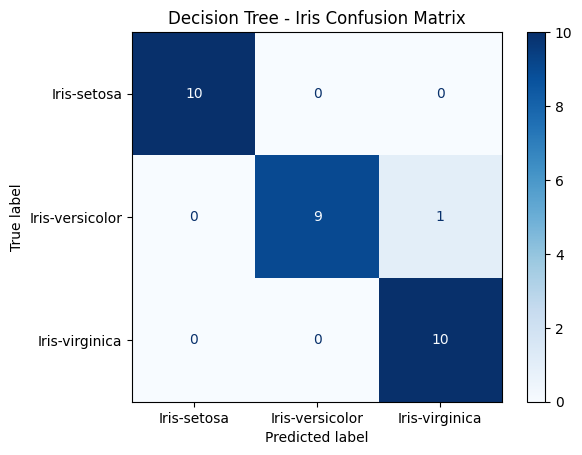

In [ ]:

# Step 7: Display the confusion matrix

cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

display.plot(cmap='Blues', values_format='d')
plt.title("Decision Tree - Iris Confusion Matrix")
plt.show()


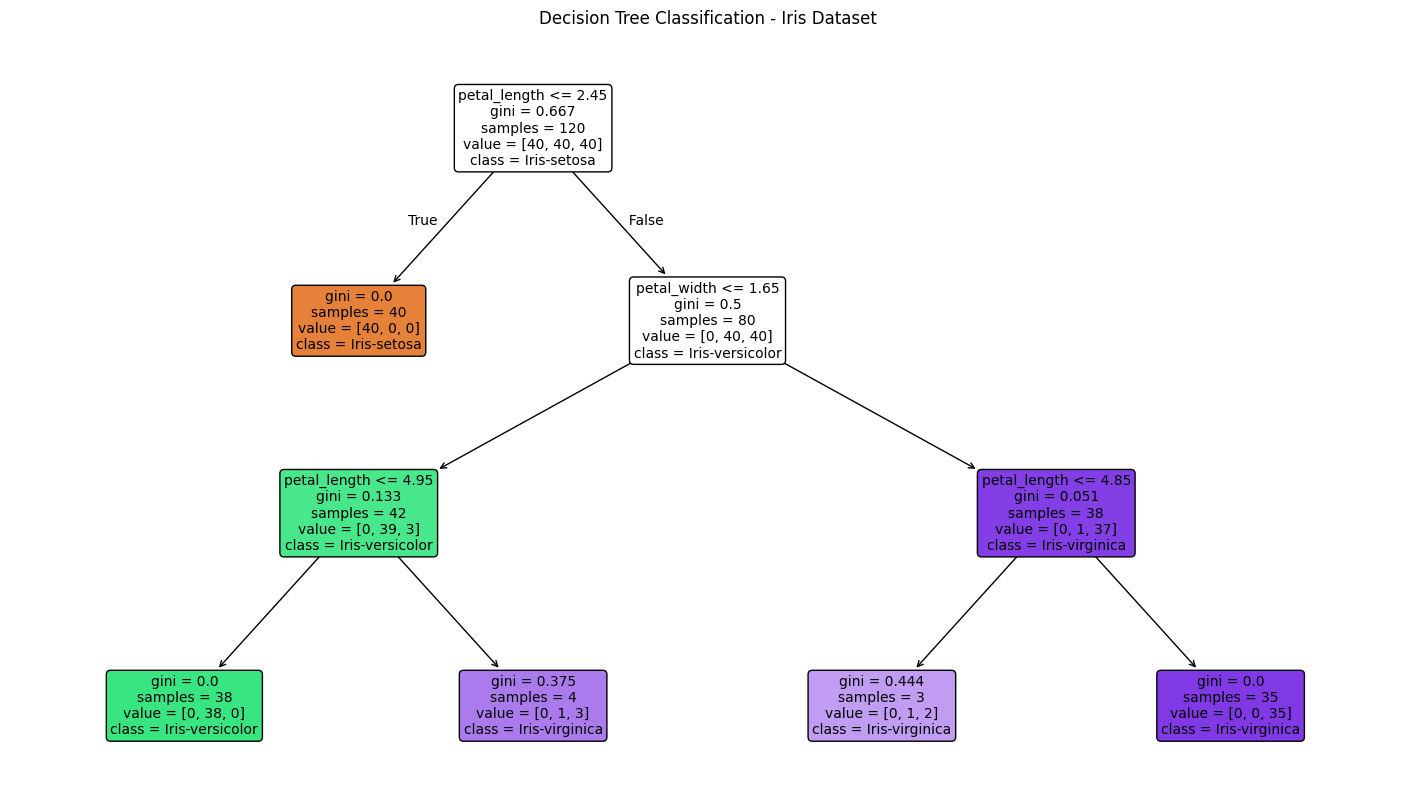

In [ ]:

# Step 8: Visualize the trained Decision Tree

plt.figure(figsize=(18, 10))

plot_tree(
    model,
    feature_names=X.columns.tolist(),
    class_names=model.classes_.tolist(),
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Decision Tree Classification - Iris Dataset")
plt.show()


In [ ]:

# Step 9: Predict the species of a new flower

new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=[
        'sepal_length',
        'sepal_width',
        'petal_length',
        'petal_width'
    ]
)

prediction = model.predict(new_flower)

print("Predicted species:", prediction[0])


Predicted species: Iris-setosa


In [ ]:

# Step 10: Final summary

print("Algorithm: Decision Tree Classifier")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Accuracy:", round(accuracy * 100, 2), "%")
print("Classes:", model.classes_)


Algorithm: Decision Tree Classifier
Training samples: 120
Testing samples: 30
Accuracy: 96.67 %
Classes: ['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']
